In [28]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df=pd.read_csv("Wine.csv")



In [29]:
print(df.head())

   Alcohol  Malic_Acid   Ash  Ash_Alcanity  Magnesium  Total_Phenols  \
0    14.23        1.71  2.43          15.6        127           2.80   
1    13.20        1.78  2.14          11.2        100           2.65   
2    13.16        2.36  2.67          18.6        101           2.80   
3    14.37        1.95  2.50          16.8        113           3.85   
4    13.24        2.59  2.87          21.0        118           2.80   

   Flavanoids  Nonflavanoid_Phenols  Proanthocyanins  Color_Intensity   Hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   OD280  Proline  Customer_Segment  
0   3.92     1065                 1  
1   3.40     105

In [30]:
print(df.describe())

          Alcohol  Malic_Acid         Ash  Ash_Alcanity   Magnesium  \
count  178.000000  178.000000  178.000000    178.000000  178.000000   
mean    13.000618    2.336348    2.366517     19.494944   99.741573   
std      0.811827    1.117146    0.274344      3.339564   14.282484   
min     11.030000    0.740000    1.360000     10.600000   70.000000   
25%     12.362500    1.602500    2.210000     17.200000   88.000000   
50%     13.050000    1.865000    2.360000     19.500000   98.000000   
75%     13.677500    3.082500    2.557500     21.500000  107.000000   
max     14.830000    5.800000    3.230000     30.000000  162.000000   

       Total_Phenols  Flavanoids  Nonflavanoid_Phenols  Proanthocyanins  \
count     178.000000  178.000000            178.000000       178.000000   
mean        2.295112    2.029270              0.361854         1.590899   
std         0.625851    0.998859              0.124453         0.572359   
min         0.980000    0.340000              0.130000      

In [31]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Alcohol               178 non-null    float64
 1   Malic_Acid            178 non-null    float64
 2   Ash                   178 non-null    float64
 3   Ash_Alcanity          178 non-null    float64
 4   Magnesium             178 non-null    int64  
 5   Total_Phenols         178 non-null    float64
 6   Flavanoids            178 non-null    float64
 7   Nonflavanoid_Phenols  178 non-null    float64
 8   Proanthocyanins       178 non-null    float64
 9   Color_Intensity       178 non-null    float64
 10  Hue                   178 non-null    float64
 11  OD280                 178 non-null    float64
 12  Proline               178 non-null    int64  
 13  Customer_Segment      178 non-null    int64  
dtypes: float64(11), int64(3)
memory usage: 19.6 KB
None


In [32]:
print(df.shape)

(178, 14)


In [33]:
print(df.columns.tolist())

['Alcohol', 'Malic_Acid', 'Ash', 'Ash_Alcanity', 'Magnesium', 'Total_Phenols', 'Flavanoids', 'Nonflavanoid_Phenols', 'Proanthocyanins', 'Color_Intensity', 'Hue', 'OD280', 'Proline', 'Customer_Segment']


In [34]:
print(df.isnull().sum())

Alcohol                 0
Malic_Acid              0
Ash                     0
Ash_Alcanity            0
Magnesium               0
Total_Phenols           0
Flavanoids              0
Nonflavanoid_Phenols    0
Proanthocyanins         0
Color_Intensity         0
Hue                     0
OD280                   0
Proline                 0
Customer_Segment        0
dtype: int64


In [35]:
x=df.drop('Customer_Segment', axis=1)
y=df['Customer_Segment']

In [36]:
scaler=StandardScaler()
x_scaled=scaler.fit_transform(x)

In [37]:
pca=PCA(n_components=2)
x_pca=pca.fit_transform(x_scaled)

In [38]:
pca_df=pd.DataFrame(x_pca, columns=['Principal Component1','Principal Component2'])
pca_df['Customer_Segment']=y.values

In [39]:
print(pca_df.head())

   Principal Component1  Principal Component2  Customer_Segment
0              3.316751              1.443463                 1
1              2.209465             -0.333393                 1
2              2.516740              1.031151                 1
3              3.757066              2.756372                 1
4              1.008908              0.869831                 1


In [40]:
print(pca.explained_variance_ratio_)

[0.36198848 0.1920749 ]


In [41]:
print(round(sum(pca.explained_variance_ratio_)*100,2),'%')

55.41 %


C:\Users\sneha\AppData\Local\Temp\ipykernel_6836\145480253.py:3: UserWarning: 
The palette list has fewer values (2) than needed (3) and will cycle, which may produce an uninterpretable plot.
  sns.scatterplot(


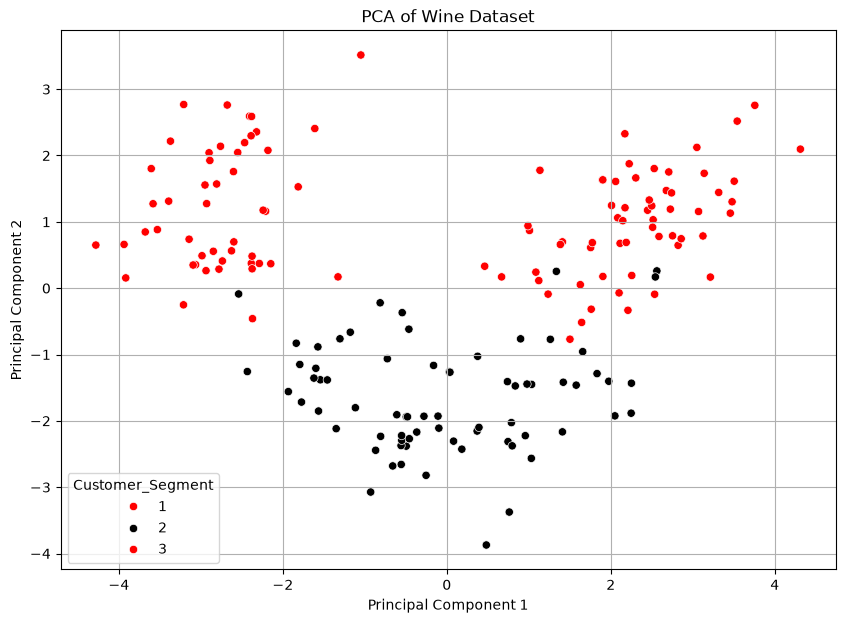

In [42]:
plt.figure(figsize=(10, 7))
import seaborn as sns
sns.scatterplot(
    x="Principal Component1",
    y="Principal Component2",
    hue="Customer_Segment",
    data=pca_df,
    palette=(["red","black"])
)

plt.title("PCA of Wine Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True)
plt.show()

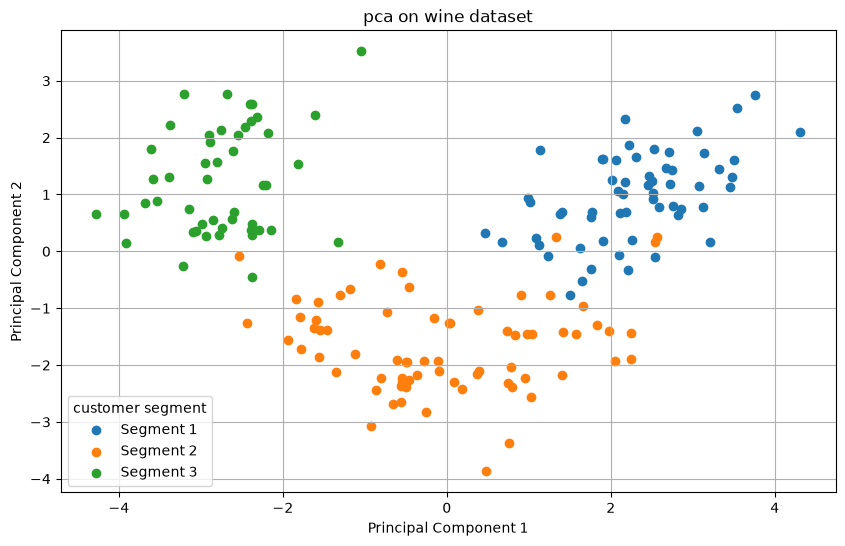

In [43]:
plt.figure(figsize=(10,6))
for seg in pca_df['Customer_Segment'].unique():
    subset=pca_df[pca_df['Customer_Segment']==seg]

    plt.scatter(
        subset['Principal Component1'],
        subset['Principal Component2'],
        label=f'Segment {seg}'
    )
plt.title('pca on wine dataset')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='customer segment')
plt.grid(True)
plt.show()

 

In [44]:
print(pca_df.columns)

Index(['Principal Component1', 'Principal Component2', 'Customer_Segment'], dtype='object')


In [45]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error,r2_score

In [46]:
df=pd.read_csv('uber.csv')

In [47]:
print(df.head())

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [48]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB
None


In [49]:
print(df.describe())

         Unnamed: 0    fare_amount  pickup_longitude  pickup_latitude  \
count  2.000000e+05  200000.000000     200000.000000    200000.000000   
mean   2.771250e+07      11.359955        -72.527638        39.935885   
std    1.601382e+07       9.901776         11.437787         7.720539   
min    1.000000e+00     -52.000000      -1340.648410       -74.015515   
25%    1.382535e+07       6.000000        -73.992065        40.734796   
50%    2.774550e+07       8.500000        -73.981823        40.752592   
75%    4.155530e+07      12.500000        -73.967154        40.767158   
max    5.542357e+07     499.000000         57.418457      1644.421482   

       dropoff_longitude  dropoff_latitude  passenger_count  
count      199999.000000     199999.000000    200000.000000  
mean          -72.525292         39.923890         1.684535  
std            13.117408          6.794829         1.385997  
min         -3356.666300       -881.985513         0.000000  
25%           -73.991407        

In [50]:
print(df.shape)

(200000, 9)


In [51]:
print(df.columns.tolist())

['Unnamed: 0', 'key', 'fare_amount', 'pickup_datetime', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'passenger_count']


In [52]:
numeric_columns=['fare_amount', 
'pickup_longitude', 'pickup_latitude', 
'dropoff_longitude', 'dropoff_latitude', 'passenger_count']

In [53]:
for col in numeric_columns:
    df[col]=pd.to_numeric(df[col], errors='coerce')

In [54]:
df['pickup_datetime']=pd.to_datetime(df['pickup_datetime'], errors='coerce')

In [55]:
df['pickup_hour']=df['pickup_datetime'].dt.hour

In [56]:
df=df.drop(columns=['Unnamed: 0', 'key', 'pickup_datetime'], errors='ignore')

In [61]:
df=df[
(df['fare_amount']>0) &
(df['passenger_count']>0) &
(df['pickup_longitude'].between(-180,180))&
(df['dropoff_longitude'].between(-180,180))&
(df['pickup_latitude'].between(-90,90))&
(df['dropoff_latitude'].between(-90,90))
]


In [62]:
df=df.fillna(df.mean(numeric_only=True))

In [63]:
df=df.dropna()

In [64]:
print(df.isnull().sum())

fare_amount          0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
pickup_hour          0
dtype: int64


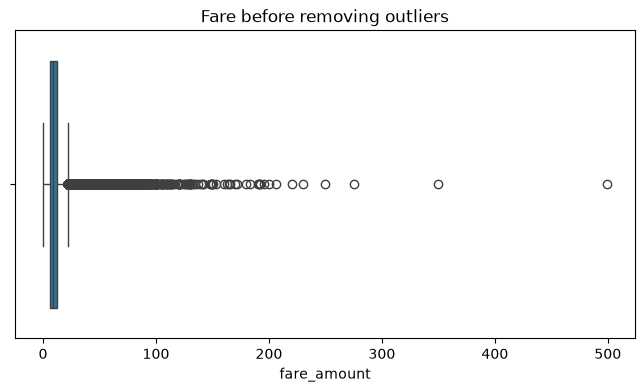

In [65]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df['fare_amount'])
plt.title('Fare before removing outliers')
plt.show()

In [66]:
Q1=df['fare_amount'].quantile(0.25)
Q3=df['fare_amount'].quantile(0.75)

IQR=Q3-Q1

Lower=Q1-1.5*IQR
Upper=Q3+1.5*IQR

df=df[(df['fare_amount']>=Lower) & (df['fare_amount']<=Upper)]

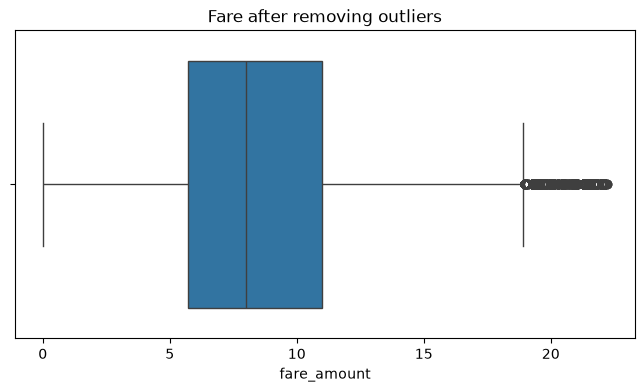

In [67]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df['fare_amount'])
plt.title('Fare after removing outliers')
plt.show()

In [68]:
correlation=df.corr(numeric_only=True)
print(correlation)

                   fare_amount  pickup_longitude  pickup_latitude  \
fare_amount           1.000000          0.000132        -0.000589   
pickup_longitude      0.000132          1.000000        -0.980175   
pickup_latitude      -0.000589         -0.980175         1.000000   
dropoff_longitude    -0.000962          0.955110        -0.942688   
dropoff_latitude      0.000544         -0.943006         0.962615   
passenger_count       0.012002         -0.000809        -0.000638   
pickup_hour          -0.013295          0.002092        -0.002281   

                   dropoff_longitude  dropoff_latitude  passenger_count  \
fare_amount                -0.000962          0.000544         0.012002   
pickup_longitude            0.955110         -0.943006        -0.000809   
pickup_latitude            -0.942688          0.962615        -0.000638   
dropoff_longitude           1.000000         -0.980726        -0.000107   
dropoff_latitude           -0.980726          1.000000        -0.001751 

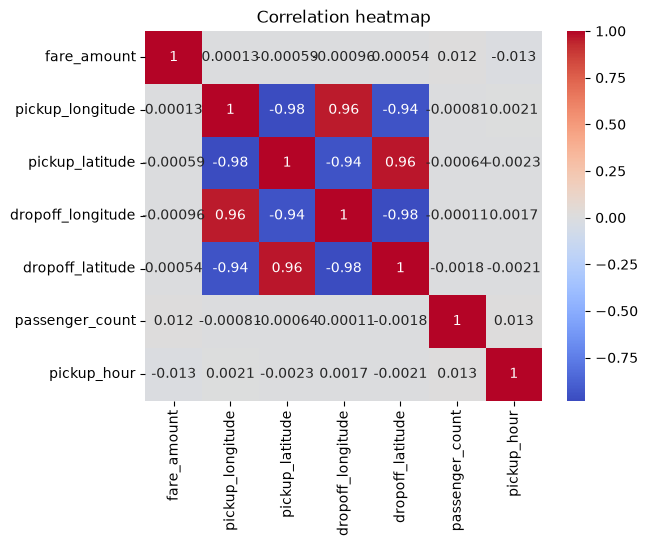

In [69]:
sns.heatmap(correlation, annot=True, cmap='coolwarm')
plt.title('Correlation heatmap')
plt.show()

In [70]:
x=df.drop(['fare_amount'], axis=1)
y=df['fare_amount']

In [71]:
x_train, x_test, y_train, y_test=train_test_split(x,y,test_size=0.20,random_state=42)

In [72]:
linear_model=LinearRegression()
Ridge_model=Ridge(alpha=1.0)
Lasso_model=Lasso(alpha=0.1)

linear_model.fit(x_train, y_train)
Ridge_model.fit(x_train, y_train)
Lasso_model.fit(x_train, y_train)

y_pred=linear_model.predict(x_test)
y_pred_rigde=Ridge_model.predict(x_test)
y_pred_lasso=Lasso_model.predict(x_test)

In [73]:
def model_evaluation(y_true, y_pred, model_name):
    r2= r2_score(y_true, y_pred)
    rmse=np.sqrt(mean_squared_error(y_true, y_pred))
    print(f" {model_name} - r2 score:{r2:.4f}, rmse score:{rmse:.4f}")

model_evaluation(y_test, y_pred, 'linear regression')
model_evaluation(y_test, y_pred_rigde, 'Ridge regression')
model_evaluation(y_test, y_pred_lasso, 'Lasso regression')


 linear regression - r2 score:-0.0000, rmse score:4.1448
 Ridge regression - r2 score:-0.0000, rmse score:4.1448
 Lasso regression - r2 score:-0.0001, rmse score:4.1449


In [74]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.datasets import load_digits

In [75]:
digits=load_digits()


In [76]:
x=digits.data
y=digits.target

In [77]:
x.shape
y.shape

(1797,)

In [78]:
x_train, x_test, y_train, y_test=train_test_split(x, y, test_size=0.20, random_state=42)

In [79]:
x_train.shape[0]
y_train.shape[0]

1437

In [80]:
clf=SVC(kernel='rbf')
clf.fit(x_train, y_train)
y_pred=clf.predict(x_test)


In [81]:
accuracy=accuracy_score(y_test, y_pred)
print(accuracy)

0.9861111111111112


In [82]:
from sklearn import metrics
cm=metrics.confusion_matrix(y_test, y_pred)
print(cm)

[[33  0  0  0  0  0  0  0  0  0]
 [ 0 28  0  0  0  0  0  0  0  0]
 [ 0  0 33  0  0  0  0  0  0  0]
 [ 0  0  0 34  0  0  0  0  0  0]
 [ 0  0  0  0 46  0  0  0  0  0]
 [ 0  0  0  0  0 46  1  0  0  0]
 [ 0  0  0  0  0  0 35  0  0  0]
 [ 0  0  0  0  0  0  0 33  0  1]
 [ 0  0  0  0  0  0  0  0 29  1]
 [ 0  0  0  0  0  1  0  1  0 38]]


In [83]:
from sklearn import metrics
cr=metrics.classification_report(y_test, y_pred)
print(cr)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        33
           1       1.00      1.00      1.00        28
           2       1.00      1.00      1.00        33
           3       1.00      1.00      1.00        34
           4       1.00      1.00      1.00        46
           5       0.98      0.98      0.98        47
           6       0.97      1.00      0.99        35
           7       0.97      0.97      0.97        34
           8       1.00      0.97      0.98        30
           9       0.95      0.95      0.95        40

    accuracy                           0.99       360
   macro avg       0.99      0.99      0.99       360
weighted avg       0.99      0.99      0.99       360



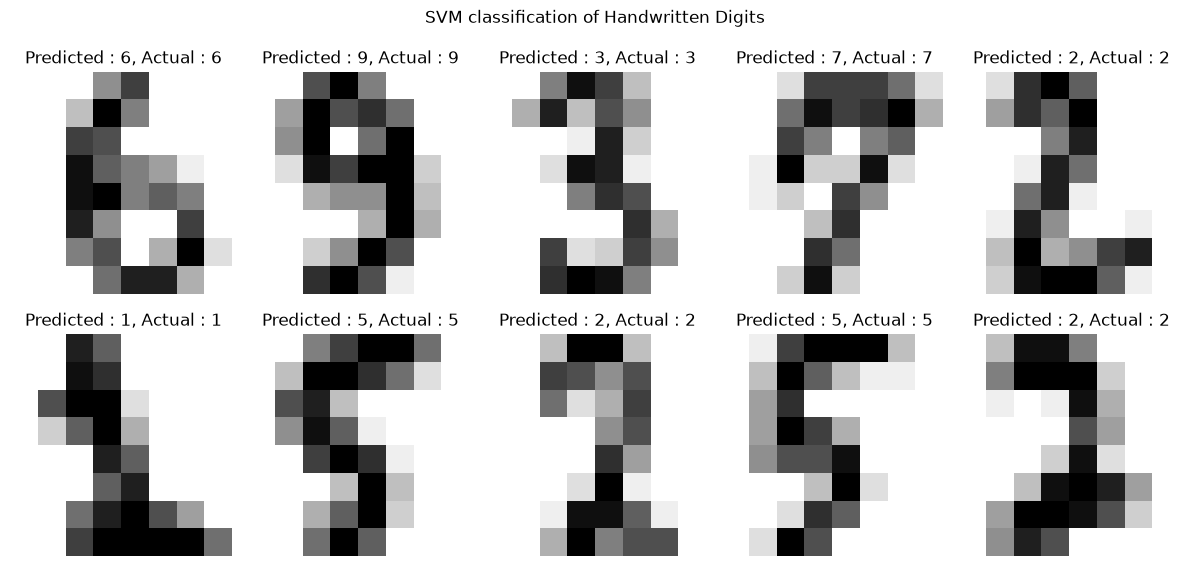

In [84]:
plt.figure(figsize=(12,6))

for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_test[i].reshape(8,8), cmap='gray_r')
    plt.title(f" Predicted : {y_pred[i]}, Actual : {y_test[i]}")
    plt.axis('off')
plt.suptitle("SVM classification of Handwritten Digits")
plt.tight_layout()
plt.show()

In [85]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

In [86]:
data = pd.read_csv("Iris.csv")

print("First 5 rows of the dataset:")
print(data.head())

print("\nDataset shape:", data.shape)

First 5 rows of the dataset:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa

Dataset shape: (150, 6)


In [87]:
X = data[
    [
        "SepalLengthCm",
        "SepalWidthCm",
        "PetalLengthCm",
        "PetalWidthCm"
    ]
]

print("Selected features:")
print(X.head())

Selected features:
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0            5.1           3.5            1.4           0.2
1            4.9           3.0            1.4           0.2
2            4.7           3.2            1.3           0.2
3            4.6           3.1            1.5           0.2
4            5.0           3.6            1.4           0.2


In [88]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

print("WCSS values:")
print(wcss)

C:\Users\sneha\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\sneha\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\sneha\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\sneha\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

WCSS values:
[680.8244000000001, 152.36870647733906, 78.940841426146, 57.317873214285704, 46.53558205128205, 38.930963049671746, 34.36020891600984, 30.023416358198972, 28.14550248961776, 25.95154437229438]


C:\Users\sneha\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\sneha\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\sneha\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


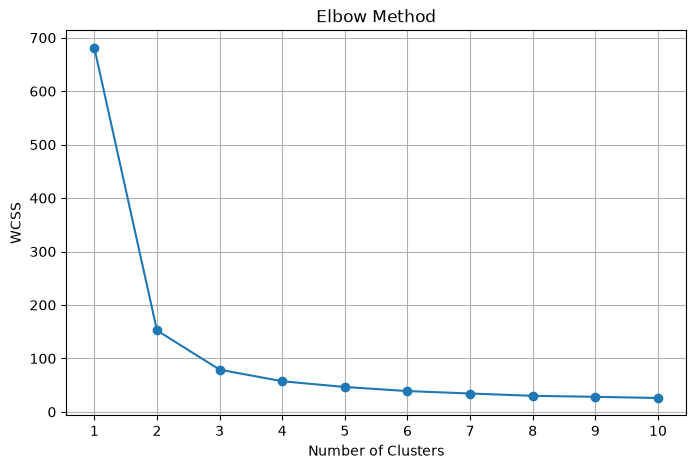

In [89]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker='o'
)

plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)

plt.show()

In [90]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X)

data["Cluster"] = clusters

C:\Users\sneha\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [91]:
print("Cluster assignments:")
print(data[["Id", "Species", "Cluster"]].head(10))

print("\nNumber of data points in each cluster:")
print(data["Cluster"].value_counts().sort_index())

Cluster assignments:
   Id      Species  Cluster
0   1  Iris-setosa        1
1   2  Iris-setosa        1
2   3  Iris-setosa        1
3   4  Iris-setosa        1
4   5  Iris-setosa        1
5   6  Iris-setosa        1
6   7  Iris-setosa        1
7   8  Iris-setosa        1
8   9  Iris-setosa        1
9  10  Iris-setosa        1

Number of data points in each cluster:
Cluster
0    62
1    50
2    38
Name: count, dtype: int64


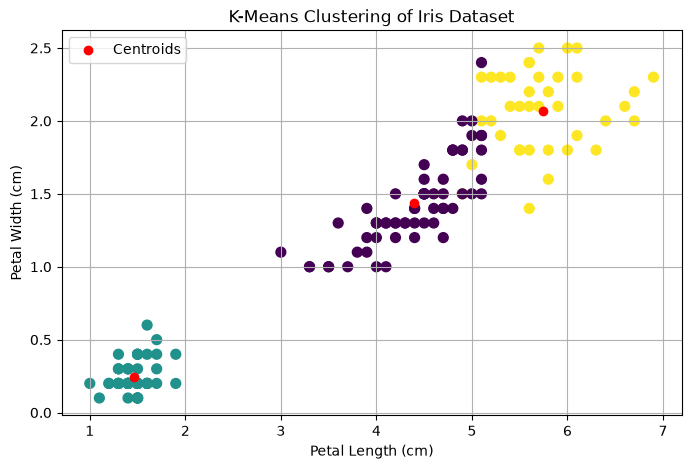

In [92]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X["PetalLengthCm"],
    X["PetalWidthCm"],
    c=clusters,
    s=50
)

centers = kmeans.cluster_centers_

plt.scatter(
    centers[:, 2],
    centers[:, 3],
    c='red',
    label="Centroids"
)

plt.title("K-Means Clustering of Iris Dataset")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.legend()
plt.grid(True)

plt.show()

In [93]:
# Random Forest Classifier for Car Evaluation

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [94]:
df = pd.read_csv("car_evaluation.csv")

print("First 5 rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

First 5 rows:
   vhigh vhigh.1  2 2.1  small   low  unacc
0  vhigh   vhigh  2   2  small   med  unacc
1  vhigh   vhigh  2   2  small  high  unacc
2  vhigh   vhigh  2   2    med   low  unacc
3  vhigh   vhigh  2   2    med   med  unacc
4  vhigh   vhigh  2   2    med  high  unacc

Dataset Shape:
(1727, 7)


In [95]:
df.columns = [
    "buying",
    "maint",
    "doors",
    "persons",
    "lug_boot",
    "safety",
    "class"
]

print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class']


In [96]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0
dtype: int64


In [97]:
X = df.drop("class", axis=1)
y = df["class"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
  buying  maint doors persons lug_boot safety
0  vhigh  vhigh     2       2    small    med
1  vhigh  vhigh     2       2    small   high
2  vhigh  vhigh     2       2      med    low
3  vhigh  vhigh     2       2      med    med
4  vhigh  vhigh     2       2      med   high

Target:
0    unacc
1    unacc
2    unacc
3    unacc
4    unacc
Name: class, dtype: object


In [98]:
encoder = LabelEncoder()

for column in X.columns:
    X[column] = encoder.fit_transform(X[column])

# Encode target variable
y_encoder = LabelEncoder()
y = y_encoder.fit_transform(y)

print("\nEncoded Features:")
print(X.head())


Encoded Features:
   buying  maint  doors  persons  lug_boot  safety
0       3      3      0        0         2       2
1       3      3      0        0         2       0
2       3      3      0        0         1       1
3       3      3      0        0         1       2
4       3      3      0        0         1       0


In [99]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.33,
    random_state=42,
    stratify=y
)

print("Training Data Shape:")
print(X_train.shape)

print("\nTesting Data Shape:")
print(X_test.shape)

Training Data Shape:
(1157, 6)

Testing Data Shape:
(570, 6)


In [100]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [101]:
model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [102]:
y_pred = model.predict(X_test)

print("Predictions:")
print(y_pred[:5])

Predictions:
[2 0 3 2 2]


In [103]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Accuracy: 0.980701754385965
Accuracy Percentage: 98.0701754385965 %


In [104]:
print("Classification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=y_encoder.classes_
    )
)

Classification Report:
              precision    recall  f1-score   support

         acc       0.96      0.95      0.96       127
        good       0.95      0.87      0.91        23
       unacc       0.99      1.00      0.99       399
       vgood       1.00      0.95      0.98        21

    accuracy                           0.98       570
   macro avg       0.98      0.94      0.96       570
weighted avg       0.98      0.98      0.98       570



In [105]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[121   1   5   0]
 [  3  20   0   0]
 [  1   0 398   0]
 [  1   0   0  20]]


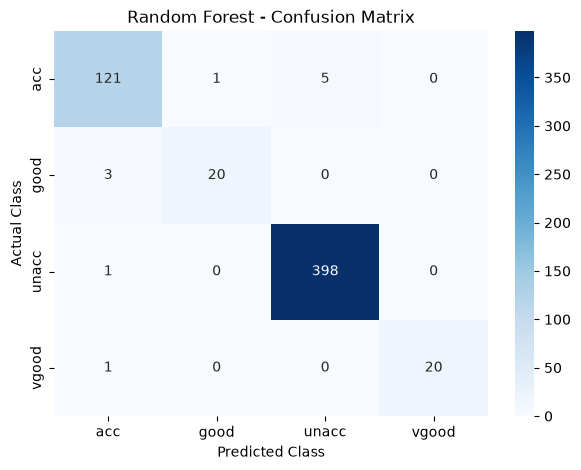

In [106]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=y_encoder.classes_,
    yticklabels=y_encoder.classes_
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Random Forest - Confusion Matrix")

plt.show()

In [107]:
feature_importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Feature Importance:")
print(feature_importance)

Feature Importance:
safety      0.273577
persons     0.222308
buying      0.171535
maint       0.167442
lug_boot    0.093228
doors       0.071910
dtype: float64


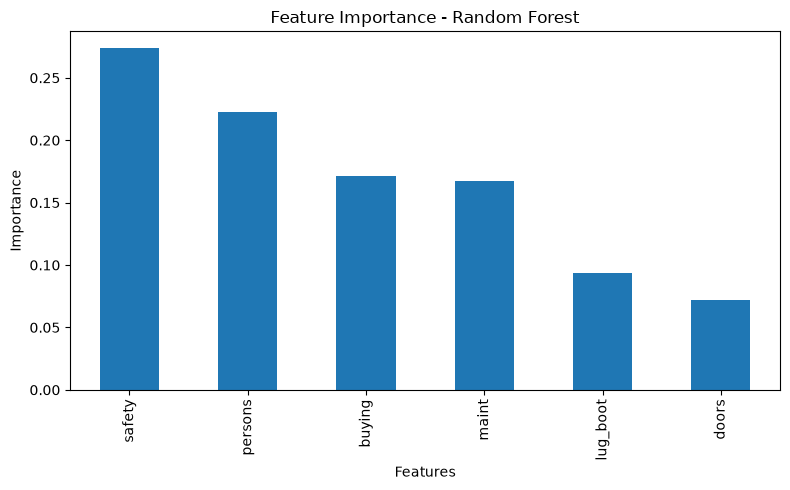

In [108]:
plt.figure(figsize=(8, 5))

feature_importance.plot(kind="bar")

plt.title("Feature Importance - Random Forest")
plt.xlabel("Features")
plt.ylabel("Importance")

plt.tight_layout()

plt.show()

In [109]:
import numpy as np
import random

In [110]:
# 0 = free path
# 1 = wall

maze = np.array([
    [0, 0, 0, 1, 0],
    [1, 1, 0, 1, 0],
    [0, 0, 0, 0, 0],
    [0, 1, 1, 1, 1],
    [0, 0, 0, 0, 0]
])

rows, cols = maze.shape

start = (0, 0)
goal = (4, 4)

print("Maze:")
print(maze)
print("\nStart:", start)
print("Goal:", goal)

Maze:
[[0 0 0 1 0]
 [1 1 0 1 0]
 [0 0 0 0 0]
 [0 1 1 1 1]
 [0 0 0 0 0]]

Start: (0, 0)
Goal: (4, 4)


In [111]:
# Actions:
# 0 = Up
# 1 = Down
# 2 = Left
# 3 = Right

actions = [
    (-1, 0),
    (1, 0),
    (0, -1),
    (0, 1)
]

# Q-table
q_table = np.zeros((rows, cols, 4))

# Learning parameters
learning_rate = 0.8
discount_factor = 0.95

epsilon = 1.0
epsilon_decay = 0.995
epsilon_min = 0.01

episodes = 1000
max_steps = 100

In [112]:
def get_next_state(state, action):

    r, c = state
    dr, dc = actions[action]

    new_r = r + dr
    new_c = c + dc

    # Check boundaries
    if new_r < 0 or new_r >= rows or new_c < 0 or new_c >= cols:
        return state

    # Check wall
    if maze[new_r, new_c] == 1:
        return state

    return (new_r, new_c)

In [113]:
for episode in range(episodes):

    state = start

    for step in range(max_steps):

        # Epsilon-greedy action selection
        if random.random() < epsilon:
            action = random.randint(0, 3)
        else:
            action = np.argmax(
                q_table[state[0], state[1]]
            )

        # Get next state
        next_state = get_next_state(state, action)

        # Calculate reward
        if next_state == goal:
            reward = 100
        elif next_state == state:
            reward = -10
        else:
            reward = -1

        # Q-learning update
        old_value = q_table[
            state[0], state[1], action
        ]

        next_max = np.max(
            q_table[next_state[0], next_state[1]]
        )

        new_value = old_value + learning_rate * (
            reward + discount_factor * next_max - old_value
        )

        q_table[
            state[0], state[1], action
        ] = new_value

        state = next_state

        # Stop when goal is reached
        if state == goal:
            break

    # Reduce exploration
    epsilon = max(epsilon_min, epsilon * epsilon_decay)

print("Training completed!")

Training completed!


In [114]:
print("Q-Table:")
print(np.round(q_table, 2))

Q-Table:
[[[ 35.84  35.84  35.84  48.26]
  [ 39.26  39.26  44.84  51.85]
  [ 42.85  55.63  48.26  42.85]
  [  0.     0.     0.     0.  ]
  [ 35.81  48.26  35.75  35.84]]

 [[  0.     0.     0.     0.  ]
  [  0.     0.     0.     0.  ]
  [ 51.85  59.61  46.63  46.63]
  [  0.     0.     0.     0.  ]
  [ 44.84  51.85  39.25  39.26]]

 [[ 59.21  72.85  59.21  63.8 ]
  [ 54.8   54.8   68.21  59.61]
  [ 55.63  50.61  63.8   55.63]
  [ 46.63  46.63  59.61  51.85]
  [ 48.26  42.85  55.63  42.85]]

 [[ 68.21  77.74  63.85  63.85]
  [  0.     0.     0.     0.  ]
  [  0.     0.     0.     0.  ]
  [  0.     0.     0.     0.  ]
  [  0.     0.     0.     0.  ]]

 [[ 72.85  68.74  68.74  82.88]
  [ 73.88  73.88  77.74  88.3 ]
  [ 79.3   79.3   82.88  94.  ]
  [ 85.    85.    88.3  100.  ]
  [  0.     0.     0.     0.  ]]]


In [115]:
state = start
path = [state]

for step in range(max_steps):

    # Select best action
    action = np.argmax(
        q_table[state[0], state[1]]
    )

    next_state = get_next_state(state, action)

    # Avoid infinite loop
    if next_state == state:
        break

    state = next_state
    path.append(state)

    # Stop at goal
    if state == goal:
        break

print("Learned Path:")
print(path)

if state == goal:
    print("\nGoal reached successfully!")
else:
    print("\nGoal could not be reached.")

Learned Path:
[(0, 0), (0, 1), (0, 2), (1, 2), (2, 2), (2, 1), (2, 0), (3, 0), (4, 0), (4, 1), (4, 2), (4, 3), (4, 4)]

Goal reached successfully!


In [116]:
display_maze = maze.astype(str)

for r, c in path:

    if (r, c) == start:
        display_maze[r, c] = "S"

    elif (r, c) == goal:
        display_maze[r, c] = "G"

    else:
        display_maze[r, c] = "*"

print("Maze with Learned Path:")

for row in display_maze:
    print(" ".join(row))

Maze with Learned Path:
S * * 1 0
1 1 * 1 0
* * * 0 0
* 1 1 1 1
* * * * G
